In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
billing_df=pd.read_csv("/content/billing.csv")
cities_df=pd.read_csv("/content/cities.csv")
complaints_df=pd.read_csv("/content/complaints.csv")
contracts_df=pd.read_csv("/content/contracts.csv")
customer_feedback_df=pd.read_csv("/content/customer_feedback.csv")

customers_df=pd.read_csv("/content/customers.csv")
data_quality_df=pd.read_csv("/content/data_quality_issue_log.csv")
devices_df=pd.read_csv("/content/devices.csv")
employees_df=pd.read_csv("/content/employees.csv")
marketing_campaigns_df=pd.read_csv("/content/marketing_campaigns.csv")

network_quality_df=pd.read_csv("/content/network_quality.csv")
payments_df=pd.read_csv("/content/payments.csv")
plan_historydf=pd.read_csv("/content/plan_history.csv")
plans_df=pd.read_csv("/content/plans.csv")
recharges_df=pd.read_csv("/content/recharges.csv")

regions_df=pd.read_csv("/content/regions.csv")
retention_campaign_df=pd.read_csv("/content/retention_campaigns.csv")
states_df=pd.read_csv("/content/states.csv")
stores_df=pd.read_csv("/content/stores.csv")
subscriptions_df=pd.read_csv("/content/subscriptions.csv")

support_tickets_df=pd.read_csv("/content/support_tickets.csv")
usage_data_df=pd.read_csv("/content/usage_data.csv")
usage_sms_df=pd.read_csv("/content/usage_sms.csv")
usage_voice_df=pd.read_csv("/content/usage_voice.csv")

In [ ]:
df = customers_df.copy()
# Define churn
df["churned"] = (
    df["churn_date"].notna()
    | df["customer_status"].astype(str).str.lower().str.strip().isin(
        ["churned", "churn"]
    )
)

# Add plan details using correct plans_df variable
df = df.merge(
    plans_df[["plan_id", "billing_cycle", "monthly_charge"]],
    on="plan_id",
    how="left",
    suffixes=("", "_plan")
)

print(df[["customer_id", "churned", "tenure_months",
          "customer_segment", "billing_cycle"]].head())

  customer_id  churned  tenure_months customer_segment billing_cycle
0    C0000001     True              2             Mass       Monthly
1    C0000002    False            146          Premium       Monthly
2    C0000003     True              1       Enterprise        Annual
3    C0000004    False            137          Premium        Annual
4    C0000005     True            108            Value       Monthly


Overall Churn Rate: 18.43%


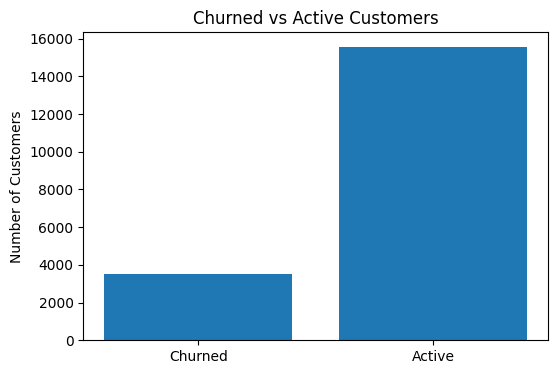

In [ ]:
total = len(df)
churned = df["churned"].sum()
active = total - churned
churn_rate = churned / total * 100 if total else 0

print(f"Overall Churn Rate: {churn_rate:.2f}%")

plt.figure(figsize=(6, 4))
plt.bar(["Churned", "Active"], [churned, active])
plt.title("Churned vs Active Customers")
plt.ylabel("Number of Customers")
plt.show()

**1. Overall churn rate — KPI card and bar chart**

Total Customers: 19,000
Churned Customers: 3,506
Active Customers: 15,494
Overall Churn Rate: 18.45%


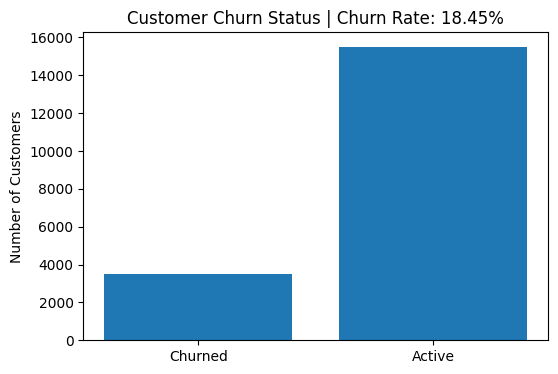

In [ ]:
total = df["customer_id"].nunique()
churned = df.loc[df["churned"], "customer_id"].nunique()
active = total - churned
churn_rate = churned / total * 100 if total else 0

print(f"Total Customers: {total:,}")
print(f"Churned Customers: {churned:,}")
print(f"Active Customers: {active:,}")
print(f"Overall Churn Rate: {churn_rate:.2f}%")

plt.figure(figsize=(6, 4))
plt.bar(["Churned", "Active"], [churned, active])
plt.title(f"Customer Churn Status | Churn Rate: {churn_rate:.2f}%")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
2

**2. Churn by billing cycle — Monthly vs Annual**

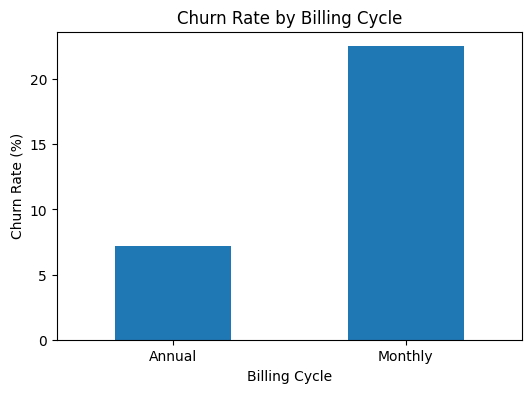

billing_cycle
Monthly    22.523939
Annual      7.162534
Name: churned, dtype: float64


In [ ]:
billing_churn = df.groupby("billing_cycle")["churned"].mean() * 100

billing_churn.plot(kind="bar", figsize=(6, 4))
plt.title("Churn Rate by Billing Cycle")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Billing Cycle")
plt.xticks(rotation=0)
plt.show()

print(billing_churn.sort_values(ascending=False))

**3. Churn by tenure band**

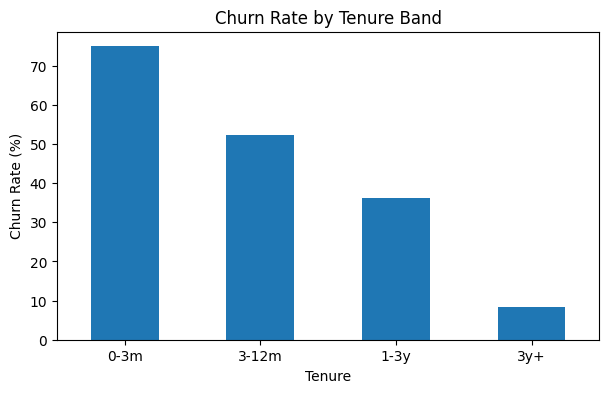

tenure_band
0-3m     74.933333
3-12m    52.233677
1-3y     36.184442
3y+       8.310763
Name: churned, dtype: float64


In [ ]:
df["tenure_band"] = pd.cut(
    df["tenure_months"],
    bins=[-1, 3, 12, 36, float("inf")],
    labels=["0-3m", "3-12m", "1-3y", "3y+"]
)

tenure_churn = df.groupby(
    "tenure_band", observed=False
)["churned"].mean() * 100

tenure_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Churn Rate by Tenure Band")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print(tenure_churn)

**4. Churn by number of unresolved complaints**

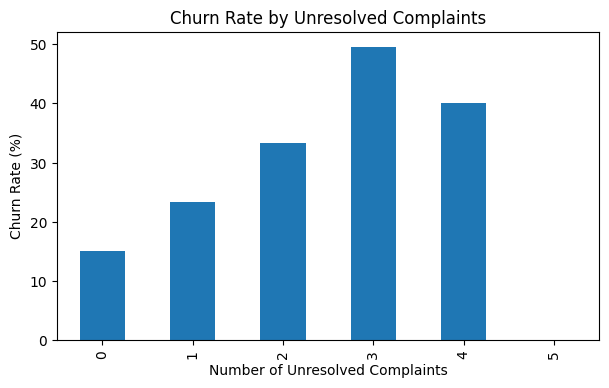

In [ ]:
unresolved = complaints[
    ~complaints["status"].astype(str).str.lower().str.strip().isin(
        ["resolved", "closed"]
    )
]

complaint_counts = unresolved.groupby("customer_id").size()

df["unresolved_complaints"] = (
    df["customer_id"].map(complaint_counts).fillna(0).astype(int)
)

complaint_churn = df.groupby(
    "unresolved_complaints"
)["churned"].mean() * 100

complaint_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Churn Rate by Unresolved Complaints")
plt.xlabel("Number of Unresolved Complaints")
plt.ylabel("Churn Rate (%)")
plt.show()

**5. Churn by customer segment**

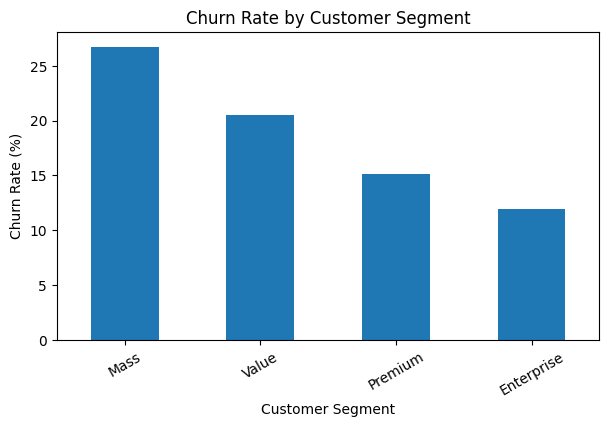

customer_segment
Mass          26.741420
Value         20.543758
Premium       15.092125
Enterprise    11.891117
Name: churned, dtype: float64


In [ ]:
segment_churn = (
    df.groupby("customer_segment")["churned"]
    .mean().mul(100).sort_values(ascending=False)
)

segment_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Churn Rate by Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Customer Segment")
plt.xticks(rotation=30)
plt.show()

print(segment_churn)

**6. Top 10 states by churned customers**

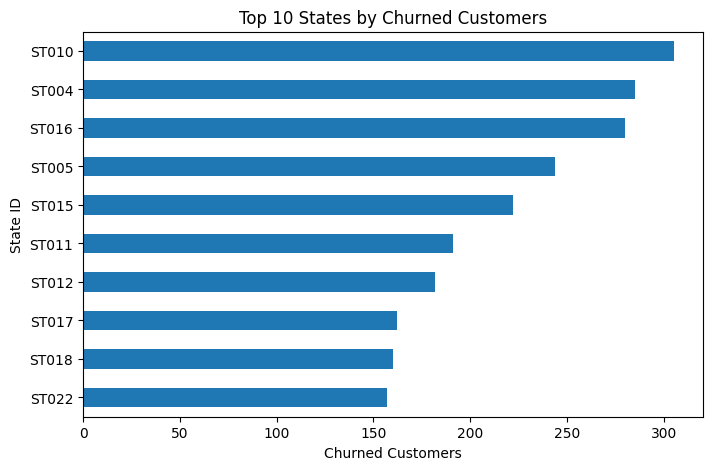

In [ ]:
top_states = (
    df[df["churned"]]
    .groupby("state_id")["customer_id"]
    .nunique()
    .nlargest(10)
    .sort_values()
)

top_states.plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 States by Churned Customers")
plt.xlabel("Churned Customers")
plt.ylabel("State ID")
plt.show()

**7. Average data usage by city tier**

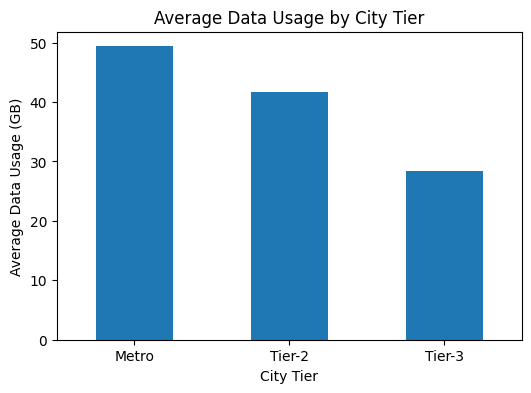

city_tier
Metro     49.366188
Tier-2    41.699290
Tier-3    28.324712
Name: avg_data_gb, dtype: float64


In [ ]:
avg_usage = usage_data.groupby("customer_id")[
    "data_gb_used"
].mean().rename("avg_data_gb")

usage_df = df.merge(avg_usage, on="customer_id", how="left")

tier_usage = usage_df.groupby("city_tier")["avg_data_gb"].mean()

tier_usage.plot(kind="bar", figsize=(6, 4))
plt.title("Average Data Usage by City Tier")
plt.ylabel("Average Data Usage (GB)")
plt.xlabel("City Tier")
plt.xticks(rotation=0)
plt.show()

print(tier_usage)

**8. ARPU distribution — Histogram**

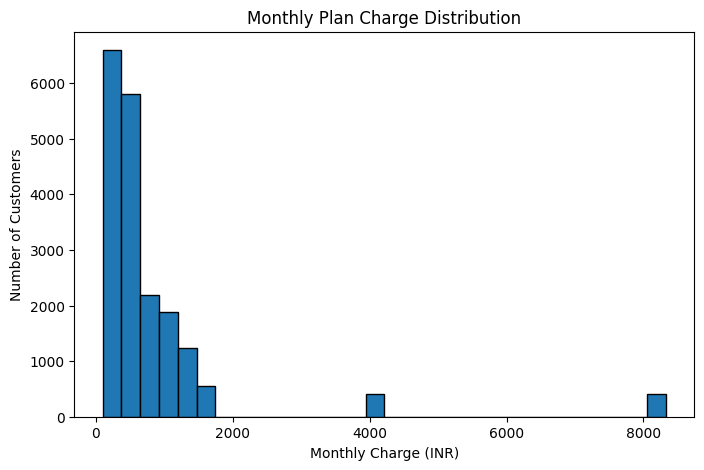

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["monthly_charge"].dropna(), bins=30, edgecolor="black")
plt.title("Monthly Plan Charge Distribution")
plt.xlabel("Monthly Charge (INR)")
plt.ylabel("Number of Customers")
plt.show()

**9. Network quality vs churn**

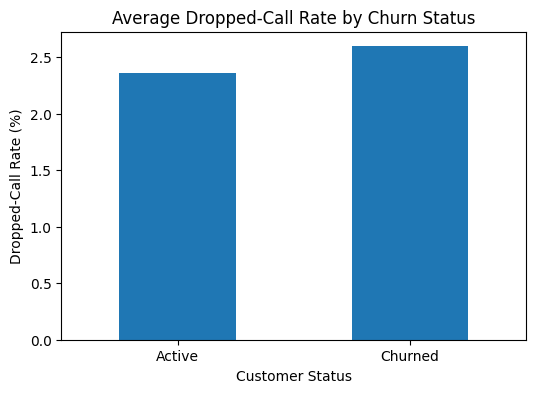

Active     2.357466
Churned    2.596869
Name: dropped_call_rate_pct, dtype: float64


In [ ]:

network_avg = network_quality_df.groupby("customer_id")[
    "dropped_call_rate_pct"
].mean().rename("dropped_call_rate_pct")

network_df = df.merge(
    network_avg, on="customer_id", how="inner"
)

network_churn = network_df.groupby("churned")[
    "dropped_call_rate_pct"
].mean()

network_churn.index = ["Active", "Churned"] if set(network_churn.index) == {False, True} else network_churn.index

plt.figure(figsize=(6, 4))
network_churn.plot(kind="bar")
plt.title("Average Dropped-Call Rate by Churn Status")
plt.ylabel("Dropped-Call Rate (%)")
plt.xlabel("Customer Status")
plt.xticks(rotation=0)
plt.show()

print(network_churn)

**10. Retention campaign outcomes and retained share**



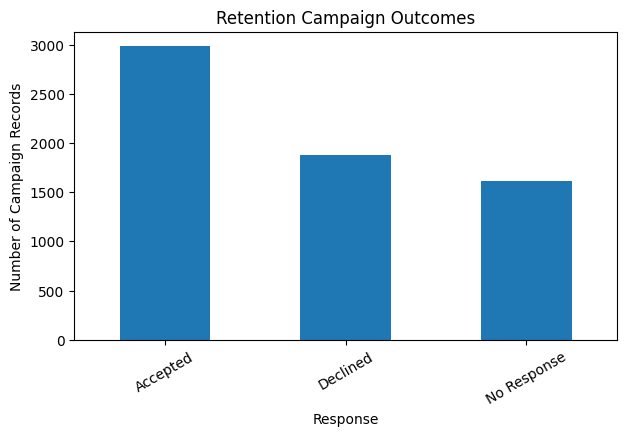

Campaign Records: 6475
Retained Customers: 5337
Retained Share: 82.42%


In [ ]:
# Campaign response counts
retention_campaign_df["response"].value_counts(
    dropna=False
).plot(kind="bar", figsize=(7, 4))

plt.title("Retention Campaign Outcomes")
plt.xlabel("Response")
plt.ylabel("Number of Campaign Records")
plt.xticks(rotation=30)
plt.show()

# Calculate retained share
retained = (
    retention_campaign_df["retained_flag"]
    .astype(str).str.lower().str.strip()
    .isin(["yes", "true", "1", "retained"]
))

print("Campaign Records:", len(retention_campaign_df))
print("Retained Customers:", retained.sum())

retained_share = retained.mean() * 100 if len(retained) else 0
print(f"Retained Share: {retained_share:.2f}%")